# Preparação para Atividade Avaliativa - Treinamento de MLPs e CNNs

O objetivo desta atividade é se preparar para a atividade avaliativa. Para isto, seleciona uma das bases de dados utilizadas anteriormente (mnist, doenças em folhas de feijão ou raios-x) e siga os passos indicados abaixo. Em caso de dúvida, veja o notebook que demonstra como treinar CNNs. 

**Importante**: Use o google colab para treinar as CNNs usando GPUs.


---

Imports básicos

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

sns.set_style('darkgrid')

### Obtenção dos Dados

Obtenha os dados usando a biblioteca kagglehub ou lendo os dados do disco.

In [2]:
# resposta
import kagglehub

ds_path = kagglehub.dataset_download("marquis03/bean-leaf-lesions-classification")
ds_path

import os

os.listdir(ds_path)

['val', 'classname.txt', 'train', 'val.csv', 'train.csv']

### Construção do Dataset do Pytorch

Implemente uma classe para representar o dataset do pytorch ou usa função pré-defina como [ImageFolder](https://debuggercafe.com/pytorch-imagefolder-for-training-cnn-models/).

A classe deve receber como entrada um atributo `transform` que realize pré-processamento nos dados e *data augmentation* no treino.


In [3]:
# resposta
from torchvision.transforms import v2
from torchvision.datasets import ImageFolder

train_transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.uint8, scale=True),
    v2.RandomResizedCrop(size=(224,224), antialias=True),
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandomRotation(degrees=30),
    v2.RandomPerspective(0.2),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

test_transform = v2.Compose([
    v2.ToImage(),
    v2.Resize((224, 224)),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.5,0.5,0.5], std=[0.5,0.5,0.5])
])

train_ds = ImageFolder(os.path.join(ds_path, 'train'), train_transform)
test_ds = ImageFolder(os.path.join(ds_path, 'val'), test_transform)

print(len(train_ds), len(test_ds))

1034 133


### Construção do Dataloader e Visualização de Exemplos

Crie dataloaders.

In [4]:
# resposta

train_loader = torch.utils.data.DataLoader(train_ds, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_ds, batch_size=64)

Mostra algumas imagens de exemplo.

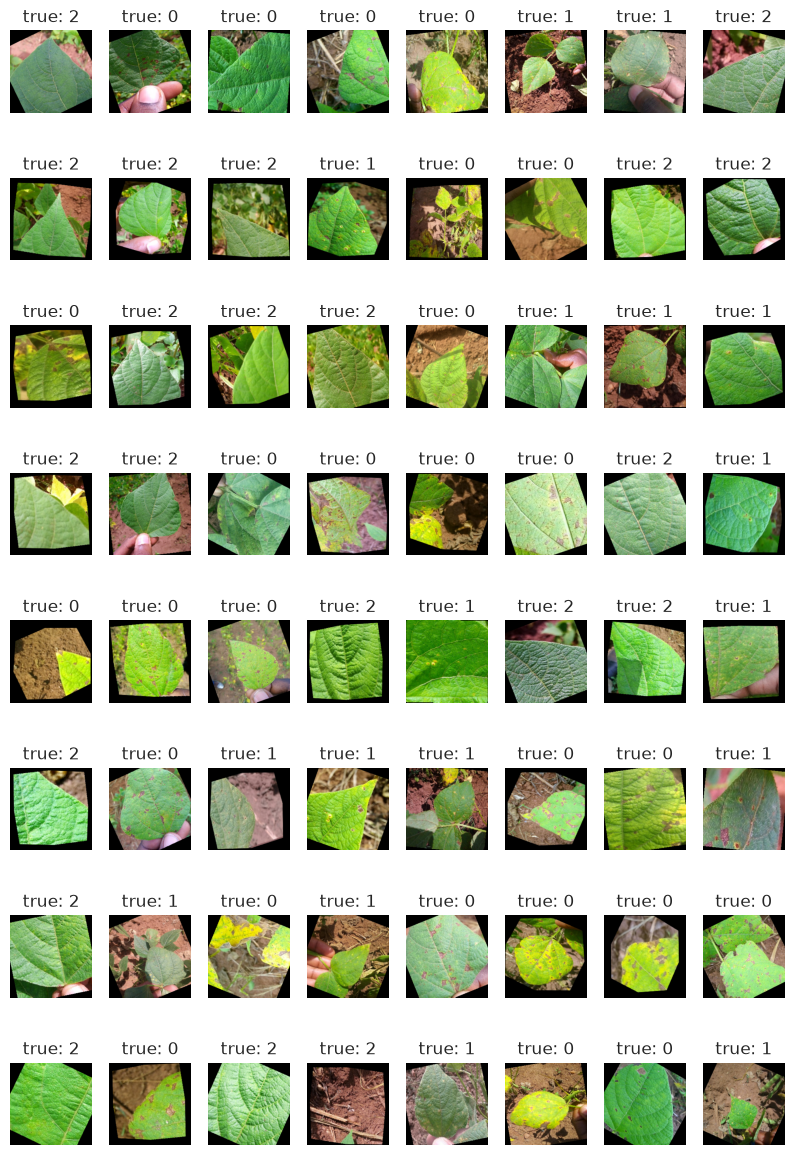

In [5]:
import matplotlib.pyplot as plt
import numpy as np

def show_batch(images, labels):
    n = len(images)
    grid_size = int(np.ceil(np.sqrt(n)))

    for idx in range(n):
        plt.subplot(grid_size, grid_size, idx + 1)
        img = images[idx].numpy()

        # muda do formato [channels, rows, cols] do torch para [rows, cols, channels]
        img = np.transpose(img, (1, 2, 0))
        img -= img.min()
        img /= img.max()

        plt.imshow(img)
        plt.grid(False)
        plt.axis('off')
        title = f'true: {labels[idx].numpy()}'
        plt.title(title)

# get some random training images
data_iter = iter(train_loader)
images, labels = next(data_iter)

plt.close('all')
plt.figure(figsize=(10, 15))
show_batch(images, labels)
plt.show()


### Definição do Modelo

Construa uma rede MLP usando `nn.Sequential`.

In [16]:
# resposta
net_mlp = nn.Sequential(
    nn.Flatten(),
    nn.Linear(3*224*224, 1024),
    nn.ReLU(),
    nn.Linear(1024, 256),
    nn.ReLU(),
    nn.Linear(256, 64),
    nn.ReLU(),
    nn.Dropout(p=0.3),
    nn.Linear(64, 3)
)

net_mlp


Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=150528, out_features=1024, bias=True)
  (2): ReLU()
  (3): Linear(in_features=1024, out_features=256, bias=True)
  (4): ReLU()
  (5): Linear(in_features=256, out_features=64, bias=True)
  (6): ReLU()
  (7): Dropout(p=0.3, inplace=False)
  (8): Linear(in_features=64, out_features=3, bias=True)
)

Construa uma rede convolucional usando `nn.Sequential`.

In [19]:
# resposta
net_conv = nn.Sequential(
    nn.Conv2d(3, 32, 5, stride=2),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),
    nn.Conv2d(32, 32, 5, stride=2),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),
    nn.Conv2d(32, 32, 5, stride=2),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),
    nn.Flatten(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Dropout(p=0.3, inplace=False),
    nn.Linear(64, 3)
)

net_conv

Sequential(
  (0): Conv2d(3, 32, kernel_size=(5, 5), stride=(2, 2))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 32, kernel_size=(5, 5), stride=(2, 2))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(32, 32, kernel_size=(5, 5), stride=(2, 2))
  (7): ReLU()
  (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (9): Flatten(start_dim=1, end_dim=-1)
  (10): Linear(in_features=128, out_features=64, bias=True)
  (11): ReLU()
  (12): Dropout(p=0.3, inplace=False)
  (13): Linear(in_features=64, out_features=3, bias=True)
)

Carregue uma rede pré-treinada e configure-a para *feature extraction*.

In [20]:
torch.cuda.is_available()

device = torch.accelerator.current_accelerator().type \
  if torch.accelerator.is_available() else "cpu"

In [21]:
# resposta
from torchvision import models

net_fex = models.resnet18(weights="IMAGENET1K_V1")

for param in net_fex.parameters():
    param.requires_grad = False


Carregue uma rede pré-treinada e configure-a para *fine-tuning*.

In [22]:
# resposta
net_ft = models.resnet18(weights="IMAGENET1K_V1")

### Treinamento e Avaliação

Escreva uma função para treinamento do modelo que receba como entrada o modelo, o dataloader de treino, o otimizador, a função de perda e o número de épocas. A função deve mostrar na tela como a acurácia evoluiu ao longo do treinamento.

In [23]:
# Otimizador
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
opt_mlp = optim.Adam(net_mlp.parameters(), lr=5e-4)
opt_conv = optim.Adam(net_conv.parameters(), lr=5e-4)
opt_fex = optim.Adam(net_fex.parameters(), lr=5e-4)
opt_ft = optim.Adam(net_ft.parameters(), lr=5e-4)

In [24]:
# resposta
from tqdm.notebook import tqdm

def train_loop(train_loader, net, opt):
    net.train()
    
    running_loss = 0.0
    all_preds = []
    all_labels = []

    for data in tqdm(train_loader):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data
        all_labels.extend(labels)

        inputs = inputs.to(device)
        labels = labels.to(device)

        # zero the parameter gradients
        opt.zero_grad()

        # forward + backward + optimize
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        opt.step()

        all_preds.extend(list(np.argmax(outputs.cpu().detach().numpy(), axis=-1)))

        # print statistics
        running_loss += loss.cpu().item()

    return all_labels, all_preds, running_loss


Escreva uma função para avaliação do modelo que receba como entrada o modelo e o dataloader de teste. A função deve mostrar na tela as métricas de acurácia, precision, recall e f1-score. 

In [25]:
# resposta
def eval_loop(test_loader, net):
    all_preds = []
    all_labels = []

    # IMPORTANTE
    # net.eval() coloca o modelo em modo de avaliação e desliga a operação de dropout
    net.eval()

    with torch.no_grad():
        for data in tqdm(test_loader):
            images, labels = data
            all_labels.extend(labels)

            # calculate outputs by running images through the network
            images = images.to(device)
            outputs = net(images).cpu().numpy()
            all_preds.extend(list(np.argmax(outputs, axis=-1)))

    return all_labels, all_preds


Use as funções para treinar e avaliar a rede MLP.


In [26]:
# resposta
from sklearn.metrics import accuracy_score

history = []

for epoch in range(10):
    true, pred, loss = train_loop(train_loader, net_mlp, opt_mlp)
    train_acc = accuracy_score(true, pred)

    true, pred = eval_loop(test_loader, net_mlp)
    test_acc = accuracy_score(true, pred)

    history.append([loss, train_acc, test_acc])
    print(f"Epoch {epoch} Loss: {loss:.2f} Train acc: {train_acc:.2f} Test acc: {test_acc:.2f} ")


  0%|          | 0/17 [00:00<?, ?it/s]

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch 0 Loss: 32.28 Train acc: 0.41 Test acc: 0.41 


  0%|          | 0/17 [00:00<?, ?it/s]

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch 1 Loss: 18.56 Train acc: 0.50 Test acc: 0.42 


... (20 outputs left out)

Epoch 8 Loss: 16.34 Train acc: 0.57 Test acc: 0.55 


  0%|          | 0/17 [00:00<?, ?it/s]

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch 9 Loss: 15.40 Train acc: 0.59 Test acc: 0.52 


Use as funções para treinar e avaliar a CNN que você construiu.


In [27]:
# resposta
history = []

for epoch in range(10):
    true, pred, loss = train_loop(train_loader, net_conv, opt_conv)
    train_acc = accuracy_score(true, pred)

    true, pred = eval_loop(test_loader, net_conv)
    test_acc = accuracy_score(true, pred)

    history.append([loss, train_acc, test_acc])
    print(f"Epoch {epoch} Loss: {loss:.2f} Train acc: {train_acc:.2f} Test acc: {test_acc:.2f} ")


  0%|          | 0/17 [00:00<?, ?it/s]

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch 0 Loss: 18.47 Train acc: 0.39 Test acc: 0.47 


  0%|          | 0/17 [00:00<?, ?it/s]

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch 1 Loss: 17.29 Train acc: 0.50 Test acc: 0.57 


... (20 outputs left out)

Epoch 8 Loss: 13.32 Train acc: 0.65 Test acc: 0.71 


  0%|          | 0/17 [00:00<?, ?it/s]

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch 9 Loss: 13.59 Train acc: 0.65 Test acc: 0.65 


Use as funções para treinar e avaliar a CNN configurada para *feature extraction*. Lembre-se definir no otimizador que apenas as últimas camadas devem ser treinadas.


In [28]:
# resposta
history = []

for epoch in range(10):
    true, pred, loss = train_loop(train_loader, net_fex, opt_fex)
    train_acc = accuracy_score(true, pred)

    true, pred = eval_loop(test_loader, net_fex)
    test_acc = accuracy_score(true, pred)

    history.append([loss, train_acc, test_acc])
    print(f"Epoch {epoch} Loss: {loss:.2f} Train acc: {train_acc:.2f} Test acc: {test_acc:.2f} ")

  0%|          | 0/17 [00:00<?, ?it/s]

RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn

Use as funções para treinar e avaliar a CNN configurada para *fine-tuning*. 


In [ ]:
# resposta
history = []

for epoch in range(10):
    true, pred, loss = train_loop(train_loader, net_ft, opt_ft)
    train_acc = accuracy_score(true, pred)

    true, pred = eval_loop(test_loader, net_ft)
    test_acc = accuracy_score(true, pred)

    history.append([loss, train_acc, test_acc])
    print(f"Epoch {epoch} Loss: {loss:.2f} Train acc: {train_acc:.2f} Test acc: {test_acc:.2f} ")


  0%|          | 0/17 [00:00<?, ?it/s]

## Análise Crítica

Escreva um parágrafo discutindo os seguintes itens: 

1. Como a acurácia evoluiu ao longo do treinamento para os diferentes modelos? Quais modelos alcançaram uma boa performance no treino? Caso algum modelo tenha alcançado uma acurácia mais de 10% inferior aos demais, dê hipóteses que possam justificar este fenômeno.

2. Os modelos generalizaram? Qual modelo alcançou melhor performance no conjunto de teste? Qual modelo você escolheria para implantar em um ambiente real considerando a tarefa específica? Justifique sua escolha.

3. Explique como as métricas precision e recall por classe devem ser interpretadas e o que podemos concluir avaliando estes valores para os diferentes modelos, e.g., o modelo priorizou uma classe sobre as demais? Alguma classe é raramente selecionada pelo modelo? 




Adiciona sua resposta aqui...
